# X-PSI with i-nessai

This notebook follows `intro-nautilus.ipynb`: the same synthetic NICER data,
star, signal and prior, with the serial importance nested sampler, **i-nessai**.

Run from the repository root using the **xpsi conda environment**. The model data
are in `examples/examples_modeling_tutorial/model_data/`. Nessai must be installed
in that environment (`python -m pip install nessai` if needed).

The final sampling cell can take a while. Adjust `nlive` and `likelihood.threads`
before running it. The notebook has deliberately been left unexecuted.

In [1]:
%matplotlib inline

import os
import numpy as np
import math
import time

from matplotlib import rcParams
rcParams['text.usetex'] = False
rcParams['font.size'] = 14.0

import xpsi

from xpsi.global_imports import gravradius
from xpsi.utilities import PlottingLibrary as XpsiPlot

/=============================================\
| X-PSI: X-ray Pulse Simulation and Inference |
|---------------------------------------------|
|                Version: 3.3.0               |
|---------------------------------------------|
|      https://xpsi-group.github.io/xpsi      |
\=============================================/

Imported emcee version: 3.1.6
Imported PyMultiNest.
Check your UltraNest installation.
Check your installation of UltraNest if using the UltranestSampler
Imported Nautilus.
Imported Nessai.
Imported GetDist version: 1.7.5
Imported nestcheck version: 0.2.1


In [2]:
data = xpsi.Data(
    counts = np.loadtxt('examples/examples_modeling_tutorial/model_data/synthetic_ST_realisation.dat', dtype=np.double),
    channels=np.arange(20,201),
    phases=np.linspace(0.0, 1.0, 33),
    first=0, last=180,
    exposure_time=226029523.452384
)

Setting channels for event data...
Channels set.


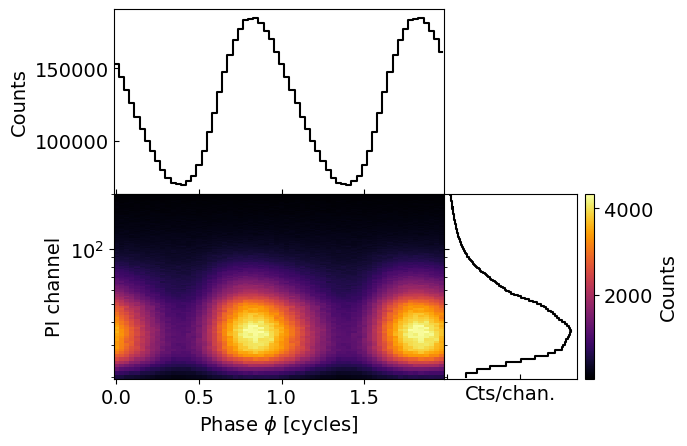

In [3]:
fig, axs = data.plot( dpi=100 , colormap='inferno' , num_rot=2)

In [4]:
NICER = xpsi.Instrument.from_ogip_fits(
    RMF_path='nicer_20170601v003.rmf',
    ARF_path='nicer_20170601v005.arf',
    datafolder='examples/examples_modeling_tutorial/model_data/'
)

# here we manually trim the instrument response files to restrict to channels 20:200
NICER.trim_response(min_channel=20, max_channel=200, tolerance=1e-4)

Loading instrument response matrix from OGIP compliant files...
Triming the response matrix because it contains columns with only 0 values.
 Now min_channel=9 and max_channel=1500
Setting channels for loaded instrument response (sub)matrix...
Channels set.
An empty subspace was created. This is normal behavior - no parameters were supplied.
Response matrix loaded.
Trimming instrument response...
Setting channels for loaded instrument response (sub)matrix...
Channels set.
Triming channels of the response matrix because a smaller channel range has been requested.
 Now min_channel=20 and max_channel=200
Triming energy inputs of the response matrix with tolerance 0.0001.
 Now min_energy=0.10000000149011612 and max_energy=9.6850004196167
Instrument response trimmed.


In [5]:
from xpsi.likelihoods.default_background_marginalisation import eval_marginal_likelihood
from xpsi.likelihoods.default_background_marginalisation import precomputation

class CustomSignal(xpsi.Signal):
    """

    A custom calculation of the logarithm of the likelihood.
    We extend the :class:`~xpsi.Signal.Signal` class to make it callable.
    We overwrite the body of the __call__ method. The docstring for the
    abstract method is copied.

    """

    def __init__(self, workspace_intervals = 1000, epsabs = 0, epsrel = 1.0e-8,
                 epsilon = 1.0e-3, sigmas = 10.0, support = None, **kwargs):
        """ Perform precomputation.

        :params ndarray[m,2] support:
            Prior support bounds for background count rate variables in the
            :math:`m` instrument channels, where the lower bounds must be zero
            or positive, and the upper bounds must be positive and greater than
            the lower bound. Alternatively, setting the an upper bounds as
            negative means the prior support is unbounded and the flat prior
            density functions per channel are improper. If ``None``, the lower-
            bound of the support for each channel is zero but the prior is
            unbounded.

        """

        super(CustomSignal, self).__init__(**kwargs)

        try:
            self._precomp = precomputation(self._data.counts.astype(np.int32))
        except AttributeError:
            print('Warning: No data... can synthesise data but cannot evaluate a '
                  'likelihood function.')
        else:
            self._workspace_intervals = workspace_intervals
            self._epsabs = epsabs
            self._epsrel = epsrel
            self._epsilon = epsilon
            self._sigmas = sigmas

            if support is not None:
                self._support = support
            else:
                self._support = -1.0 * np.ones((self._data.counts.shape[0],2))
                self._support[:,0] = 0.0

    def __call__(self, *args, **kwargs):
        self.loglikelihood, self.expected_counts, self.background_signal, self.background_given_support = \
                eval_marginal_likelihood(
                    self._data.exposure_time,
                    self._data.phases,
                    self._data.counts,
                    self._signals,
                    self._phases,
                    self._shifts,
                    self._precomp,
                    self._support,
                    self._workspace_intervals,
                    self._epsabs,
                    self._epsrel,
                    self._epsilon,
                    self._sigmas,
                    kwargs.get('llzero'),
                    allow_negative=False,
                    slim=20.0,  # restore fast flux rejection for obviously poor fits
                )

In [6]:
signal = CustomSignal(
    data = data,
    instrument = NICER,
    background = None,
    interstellar = None,
    workspace_intervals = 1000,
    cache = True,
    epsrel = 1.0e-8,
    epsilon = 1.0e-3,
    sigmas = 10.0,
    support = None
)

Creating parameter:
    > Named "phase_shift" with fixed value 0.000e+00.
    > The phase shift for the signal, a periodic parameter [cycles].


In [7]:
bounds = dict(
    mass = (1.0, 3.0),                       # mass with default bounds
    radius = (3.0 * gravradius(1.0), 16.0),  # equatorial radius
) 

values = dict(
    frequency=200.0,                           # Fixed spin frequency
    distance = 5.2,                     # distance in kpc
    cos_inclination = 0.4
)                          

spacetime = xpsi.Spacetime(bounds=bounds, values=values)

Creating parameter:
    > Named "frequency" with fixed value 2.000e+02.
    > Spin frequency [Hz].
Creating parameter:
    > Named "mass" with bounds [1.000e+00, 3.000e+00].
    > Gravitational mass [solar masses].
Creating parameter:
    > Named "radius" with bounds [4.430e+00, 1.600e+01].
    > Coordinate equatorial radius [km].
Creating parameter:
    > Named "distance" with fixed value 5.200e+00.
    > Earth distance [kpc].
Creating parameter:
    > Named "cos_inclination" with fixed value 4.000e-01.
    > Cosine of Earth inclination to rotation axis.


In [8]:
bounds = dict(
    super_radius = (None, None),      # radius of the hot spot, in radians (default: between 0 and pi/2 (half of the NS))
    phase_shift = (-0.25, 0.75),      # longitude of the hot spot
    super_temperature = (None, None) # temperature of the hot spot, default: 3.0 to 7.6, from very cold to very hot
)

values = dict(
    super_colatitude=0.9
)  # latitude of the hot spot in radians, from north pole (default: 0) to south pole (default: pi)

# a simple circular, simply-connected spot
primary = xpsi.HotRegion(
    bounds=bounds,
    values=values, 
    symmetry=True,
    omit=False,
    cede=False,
    concentric=False,
    sqrt_num_cells=8,
    min_sqrt_num_cells=4,
    max_sqrt_num_cells=16,
    num_leaves=16,
    num_rays=50,
    atm_ext="BB", # default blackbody, other options: "Num4D" or "user"
    prefix='p'
)   # unique prefix to identify the region, needed if >1 instances

Creating parameter:
    > Named "super_colatitude" with fixed value 9.000e-01.
    > The colatitude of the centre of the superseding region [radians].
Creating parameter:
    > Named "super_radius" with bounds [0.000e+00, 1.571e+00].
    > The angular radius of the (circular) superseding region [radians].
Creating parameter:
    > Named "phase_shift" with bounds [-2.500e-01, 7.500e-01].
    > The phase of the hot region, a periodic parameter [cycles].
Creating parameter:
    > Named "super_temperature" with bounds [3.000e+00, 7.600e+00].
    > log10(superseding region effective temperature [K]).


In [9]:
photosphere = xpsi.Photosphere(hot = primary, elsewhere = None,
                                values=dict(mode_frequency = spacetime['frequency']))

Creating parameter:
    > Named "mode_frequency" with fixed value 2.000e+02.
    > Coordinate frequency of the mode of radiative asymmetry in the
photosphere that is assumed to generate the pulsed signal [Hz].


In [10]:
star = xpsi.Star(spacetime = spacetime, photospheres = photosphere)

In [11]:
from scipy.stats import truncnorm

class CustomPrior(xpsi.Prior):
    """ A custom (joint) prior distribution.

    Source: Fictitious
    Model variant: ST-U
        Two single-temperature, simply-connected circular hot regions with
        unshared parameters.

    """

    __derived_names__ = ['compactness', ]
    __draws_from_support__ = 3

    def __init__(self):
        """ Nothing to be done.

        A direct reference to the spacetime object could be put here
        for use in __call__:

        .. code-block::

            self.spacetime = ref

        Instead we get a reference to the spacetime object through the
        a reference to a likelihood object which encapsulates a
        reference to the spacetime object.

        """
        super(CustomPrior, self).__init__() # not strictly required if no hyperparameters

    def __call__(self, p = None):
        """ Evaluate distribution at ``p``.

        :param list p: Model parameter values.

        :returns: Logarithm of the distribution evaluated at ``p``.

        """
        temp = super(CustomPrior, self).__call__(p)
        if not np.isfinite(temp):
            return temp

        # based on contemporary EOS theory
        if not self.parameters['radius'] <= 16.0:
            return -np.inf

        ref = self.parameters.star.spacetime # shortcut

        # limit polar radius to try to exclude deflections >= \pi radians
        # due to oblateness this does not quite eliminate all configurations
        # with deflections >= \pi radians
        R_p = 1.0 + ref.epsilon * (-0.788 + 1.030 * ref.zeta)
        if R_p < 1.76 / ref.R_r_s:
            return -np.inf

        # polar radius at photon sphere for ~static star (static ambient spacetime)
        #if R_p < 1.5 / ref.R_r_s:
        #    return -np.inf

        mu = math.sqrt(-1.0 / (3.0 * ref.epsilon * (-0.788 + 1.030 * ref.zeta)))

        # 2-surface cross-section have a single maximum in |z|
        # i.e., an elliptical surface; minor effect on support, if any,
        # for high spin frequenies
        if mu < 1.0:
            return -np.inf

        ref = self.parameters # redefine shortcut

        return 0.0

    def inverse_sample(self, hypercube=None):
        """ Draw sample uniformly from the distribution via inverse sampling. """

        to_cache = self.parameters.vector

        if hypercube is None:
            hypercube = np.random.rand(len(self))

        # the base method -a uniform sampling within the bounds- is useful, so to avoid writing that code again:
        _ = super(CustomPrior, self).inverse_sample(hypercube)

        ref = self.parameters # shortcut

        # restore proper cache
        for parameter, cache in zip(ref, to_cache):
            parameter.cached = cache

        # it is important that we return the desired vector because it is
        # automatically written to disk by MultiNest and only by MultiNest
        return self.parameters.vector

    def transform(self, p, **kwargs):
        """ A transformation for post-processing. """

        p = list(p) # copy

        # used ordered names and values
        ref = dict(zip(self.parameters.names, p))

        # compactness ratio M/R_eq
        p += [gravradius(ref['mass']) / ref['radius']]

        return p

In [12]:
prior = CustomPrior()

An empty subspace was created. This is normal behavior - no parameters were supplied.


In [13]:
likelihood = xpsi.Likelihood(star = star, signals = signal,
                             prior = prior,
                             num_energies=128,
                             threads=1,
                             externally_updated=False,
                             llzero=-1.0e8)  # the Nessai wrapper clamps rejection values below

In [14]:
likelihood

Free parameters
---------------
mass: Gravitational mass [solar masses].
radius: Coordinate equatorial radius [km].
p__phase_shift: The phase of the hot region, a periodic parameter [cycles].
p__super_radius: The angular radius of the (circular) superseding region [radians].
p__super_temperature: log10(superseding region effective temperature [K]).

In [15]:
p = [1.4,      # mass
     12.0,     # radius
     0.1,      # p__phase_shift
     0.2,      # p__super_radius
     6.15]     # p__super_temperature

## You can evaluate the likelihood for the parameters p
print(likelihood(p, reinitialise=True))   # use reinitialise=True if settings have been changed since the last call of the likelihood (here it is not necessary)

## Or check that you get the expected likelihood value
likelihood.clear_cache()
t = time.time()

print('time = %.3f s' % (time.time() - t))

-27564.365898942167
time = 0.000 s


## Run i-nessai

`sampler_build_kwargs` goes to [Nessai's FlowSampler](https://nessai.readthedocs.io/en/stable/autoapi/nessai/flowsampler/index.html),
including the number of live points, stopping tolerance and output directory.
The wrapper defaults to `importance_nested_sampler=True`; it is also set
explicitly below. The i-nessai stopping setting is `tolerance`, with the default
log-evidence-ratio criterion (`ratio`).
`runtime_params` goes to `FlowSampler.run`. See the
[i-nessai guide](https://nessai.readthedocs.io/en/stable/importance-nested-sampling.html).
The optional final redraw is left disabled (the Nessai default): in the installed
Nessai 0.15.2, `redraw_samples=True` fails with a missing
`ImportanceFlowProposal.unnormalised_weights` attribute. The default path
produces posterior samples without that extra redraw.

The adapter calls `prior.inverse_sample` for each likelihood evaluation, retaining
the prior transforms and constraints used above. Native Nessai output and plots
use unit-cube coordinates (`u_mass`, `u_radius`, etc.); use
`sampler.posterior_samples` below for physical parameters. This basic integration
does not export X-PSI run files.

This configuration starts a fresh run in `OutputNessaiClamped` with `resume=False`.
The previous run is preserved in `OutputNessaiFastRejection`. Nessai checkpoints
retain sampler settings and stored likelihoods, so do not resume the old run
with the new floor or threshold settings.

The signal keeps `slim=20.0` for fast flux rejection. The Nessai wrapper applies
`log_likelihood_floor=-1e6`: all lower values, including X-PSI's randomized
rejections between `-1e8` and `-1e7`, become exactly `-1e6`. Higher likelihoods
are unchanged. This floor changes the likelihood in the rejected region; its
contribution should be negligible for the useful likelihoods observed here.
Choose a floor well below the posterior region for any other problem.

`strict_threshold=True` keeps newly evaluated below-threshold points out of the
live set. The quantile threshold uses your `q=0.8` and `min_samples=500` settings.
Before training, the wrapper checks that there are enough points above the floor
and that the first threshold clears the constant plateau. If it does not, it
raises an explanatory error instead of reporting premature convergence.
Rejected draws remain in the evidence bookkeeping and may still appear in plots
of all samples. These settings do not prevent the flow from proposing poor fits.

Restart the kernel before running the updated cells. These changes have not been
executed in this notebook. The separate Nessai evidence-uncertainty underflow
warning can still occur.


In [ ]:
from nessai.utils import configure_logger

configure_logger(output='OutputNessaiClamped', log_level='INFO')

sampler_build_kwargs = {
    'importance_nested_sampler': True,  # the wrapper default
    'nlive': 5_000,
    'output': 'OutputNessaiClamped',
    'resume': False,  # fresh run: old checkpoints use a different likelihood
    'seed': 42,
    #'stopping_criterion': 'ratio',
    #'tolerance': 0.0,
    'pytorch_threads': 1,
    'signal_handling': False,  # keep Jupyter's interrupt handling
}

sampler_build_kwargs.update({
   # "threshold_method": "quantile",
    #"threshold_kwargs": {"q": 0.8},
    #"min_samples": 500,
    #"strict_threshold": True
})

runtime_params = {
    'plot': True,
    'save': True,
    'redraw_samples': False,  # Nessai default; see note above
}

likelihood.threads = 8  # increase to suit your machine
likelihood.reinitialise()
likelihood.clear_cache()
likelihood.externally_updated = True

sampler = xpsi.Sample.run_nessai(
    likelihood,
    prior,
    sampler_build_kwargs=sampler_build_kwargs,
    runtime_params=runtime_params,
    log_likelihood_floor=-1.0e6,  # clamp all lower values to this constant
)

09-15 15:54 nessai INFO    : Running Nessai version 0.15.2
09-15 15:54 nessai INFO    : pool and n_pool are none, no multiprocessing pool
09-15 15:54 nessai WARNING : Extra parameter `logW` has already been added. Skipping.Call `reset_extra_live_points_parameters` to reset the values and add this parameter.
09-15 15:54 nessai WARNING : Extra parameter `logQ` has already been added. Skipping.Call `reset_extra_live_points_parameters` to reset the values and add this parameter.
09-15 15:54 nessai WARNING : Extra parameter `logU` has already been added. Skipping.Call `reset_extra_live_points_parameters` to reset the values and add this parameter.
09-15 15:54 nessai INFO    : Initialising nested sampler
09-15 15:54 nessai WARNING : Multiprocessing pool has already been configured.
09-15 15:54 nessai INFO    : Stopping criteria: CriterionGroup(criteria=[LogEvidenceRatio(name='log_evidence_ratio', tolerance=0.0, comparison='<=')], mode='or')
09-15 15:54 nessai WARNING : Signal handling is dis

## Inspect the physical posterior

Rows of `samples` are equal-weight posterior draws. Columns follow
`likelihood.names`; fixed parameters and derived quantities are not included.
The underlying Nessai sampler is available as `sampler._sampler`.

In [ ]:
samples = sampler.posterior_samples
print('Parameter order:', likelihood.names)
print('Posterior shape:', samples.shape)
print('log Z:', sampler._sampler.log_evidence)
print('log Z error:', sampler._sampler.log_evidence_error)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(
    samples[:, likelihood.index('mass')],
    samples[:, likelihood.index('radius')],
    s=3, alpha=0.3,
)
ax.set(xlabel=r'Mass [$M_\odot$]', ylabel='Radius [km]')
plt.show()